In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
for f in fm.findSystemFonts():
    if "times" in f.lower():
        prop = fm.FontProperties(fname=f)
        print(f, " -> ", prop.get_name())

In [3]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [8]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc')
        tke = flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].mean('time')
        tke_std = (flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].std('time')/np.sqrt(2*12*50)).rename('tke_std')
        dw_lwa = xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].mean('time')
        dw_lwa_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].std('time')/np.sqrt(2*365*50)).rename('dw_lwa_std')
        print(tke_std.shape,tke.shape,dw_lwa_std.shape,dw_lwa.shape)
        ds = xr.merge([tke,dw_lwa,tke_std,dw_lwa_std])
        ds.to_netcdf(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)

# Load blocking data
DA_clims = []

for i,experiment in tqdm(enumerate(experiments)):
    if i<=1:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')
    if i>1:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')
    #DA_clims.append((xr.where(ds['LWAA_tracked']>0,1,0).mean('time'))*100)
    DA_clims.append(ds['LWAA_freq'])
    ds.close()

4it [00:01,  2.22it/s]


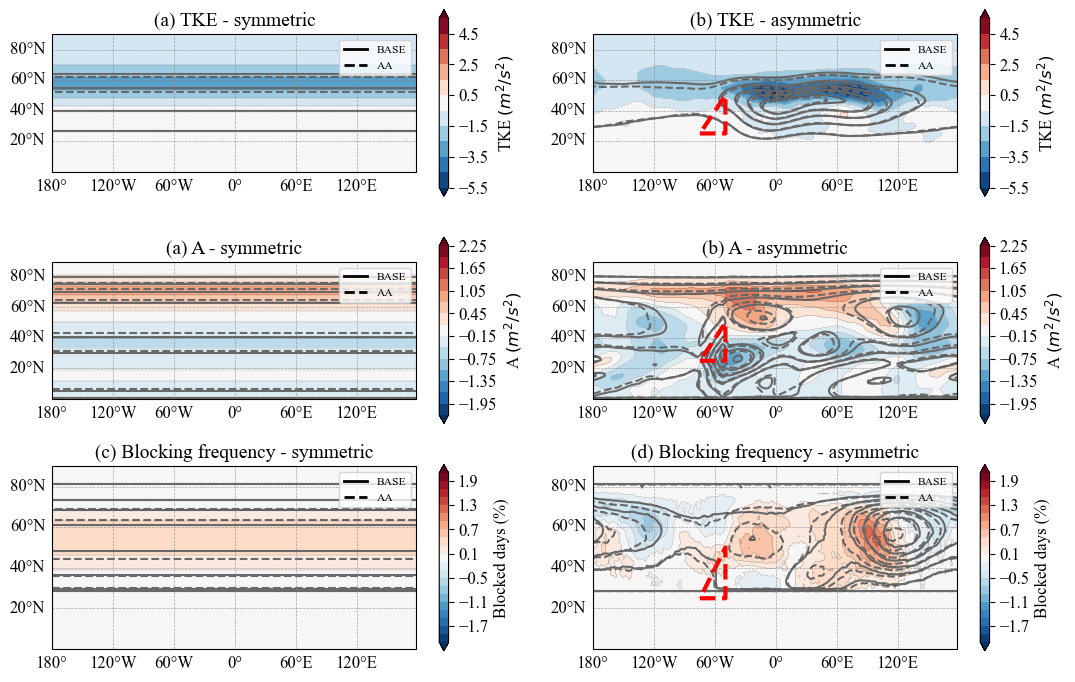

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.lines import Line2D  # <-- Add this import at the top of your cell

fig, ax = plt.subplots(3, 2, figsize=(11, 7), subplot_kw={'projection': ccrs.PlateCarree()})
ax = ax.T.flatten()  # transpose then flatten: ordering = [col0_row1, col0_row2, col0_row3, col1_row1, col1_row2, col1_row3]

titles = ['symmetric', 'asymmetric']
letters = ['(a)','(a)','(c)','(b)','(b)','(d)']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

for i in range(2):
    base = i * 3
    ax_tke = ax[base + 0]    # row 1 of column i
    ax_lwa = ax[base + 1]    # row 2 of column i
    ax_block = ax[base + 2]  # row 3 of column i (this places blocking in the last row)
    if i == 0:
        ds_a = ds_clims[i * 2].mean('lon').broadcast_like(ds_clims[i*2]).transpose()     # baseline
        ds_b = ds_clims[i * 2 + 1].mean('lon').broadcast_like(ds_clims[i*2]).transpose()  # AA
        da_a_block = DA_clims[i * 2].mean('lon').broadcast_like(ds_clims[i*2]).transpose()  
        da_b_block = DA_clims[i * 2 + 1].mean('lon').broadcast_like(ds_clims[i*2]).transpose() 
    if i == 1:
        ds_a = ds_clims[i * 2]     # baseline
        ds_b = ds_clims[i * 2 + 1] # AA
        da_a_block = DA_clims[i * 2] 
        da_b_block = DA_clims[i * 2 + 1]
        

    # TKE
    levels_tke = np.linspace(0, 100, 10)
    levels_tke_diff = np.arange(-5.5, 6, 1)
    ax_tke.set_title(f'{letters[i*3+0]} TKE - {titles[i]}')
    cont = ax_tke.contour(ds_a['lon'], ds_a['lat'], ds_a['tke'], levels=levels_tke, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_tke.contour(ds_b['lon'], ds_b['lat'], ds_b['tke'], levels=levels_tke, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh = ax_tke.contourf(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'],
                         levels=levels_tke_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_tke.contour(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'],
                    levels=levels_tke_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_tke.set_aspect(1.5)
#    ax_tke.clabel(cont,colors='k')
    fig.colorbar(sh, ax=ax_tke, orientation='vertical', label='TKE $(m^2/s^2)$')
    if i > 0:
        ax_tke.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl0 = ax_tke.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl0.top_labels = False
    gl0.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_tke.legend(handles=custom_lines, loc='upper right',fontsize='x-small')

    # dw_lwa
    levels_lwa = np.linspace(5, 25, 8)
    levels_lwa_diff = np.arange(-2.25, 2.3, 0.3)
    ax_lwa.set_title(f'{letters[i*3+1]} A - {titles[i]}')
    cont = ax_lwa.contour(ds_a['lon'], ds_a['lat'], ds_a['dw_lwa'], levels=levels_lwa, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_lwa.contour(ds_b['lon'], ds_b['lat'], ds_b['dw_lwa'], levels=levels_lwa, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh2 = ax_lwa.contourf(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'],
                          levels=levels_lwa_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_lwa.contour(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'],
                    levels=levels_lwa_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_lwa.set_aspect(1.5)
#    ax_lwa.clabel(cont,colors='k')
    fig.colorbar(sh2, ax=ax_lwa, orientation='vertical', label='A $(m^2/s^2)$')
    if i > 0:
        ax_lwa.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl1 = ax_lwa.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl1.top_labels = False
    gl1.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_lwa.legend(handles=custom_lines, loc='upper right',fontsize='x-small')
    
    # Blocking frequency (placed on the third row of each column)
    levels_block = np.arange(0, 12, 1)    # percent
    levels_block_diff = np.arange(-2.1, 2.2, 0.2)
    ax_block.set_title(f'{letters[i*3+2]} Blocking frequency - {titles[i]}')
    cont = ax_block.contour(ds_a['lon'], ds_a['lat'], da_a_block, levels=levels_block, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_block.contour(ds_b['lon'], ds_b['lat'], da_b_block, levels=levels_block, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh3 = ax_block.contourf(ds_a['lon'], ds_a['lat'], da_b_block - da_a_block,
                            levels=levels_block_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_block.contour(ds_a['lon'], ds_a['lat'], da_b_block - da_a_block,
                     levels=levels_block_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_block.set_aspect(2)
#    ax_block.clabel(cont,colors='k')
    fig.colorbar(sh3, ax=ax_block, orientation='vertical', label='Blocked days (%)')
    if i > 0:
        ax_block.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    glb = ax_block.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    glb.top_labels = False
    glb.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_block.legend(handles=custom_lines, loc='upper right',fontsize='x-small')

plt.tight_layout()
plt.savefig('PLOTS/Figure5.png',dpi=300)

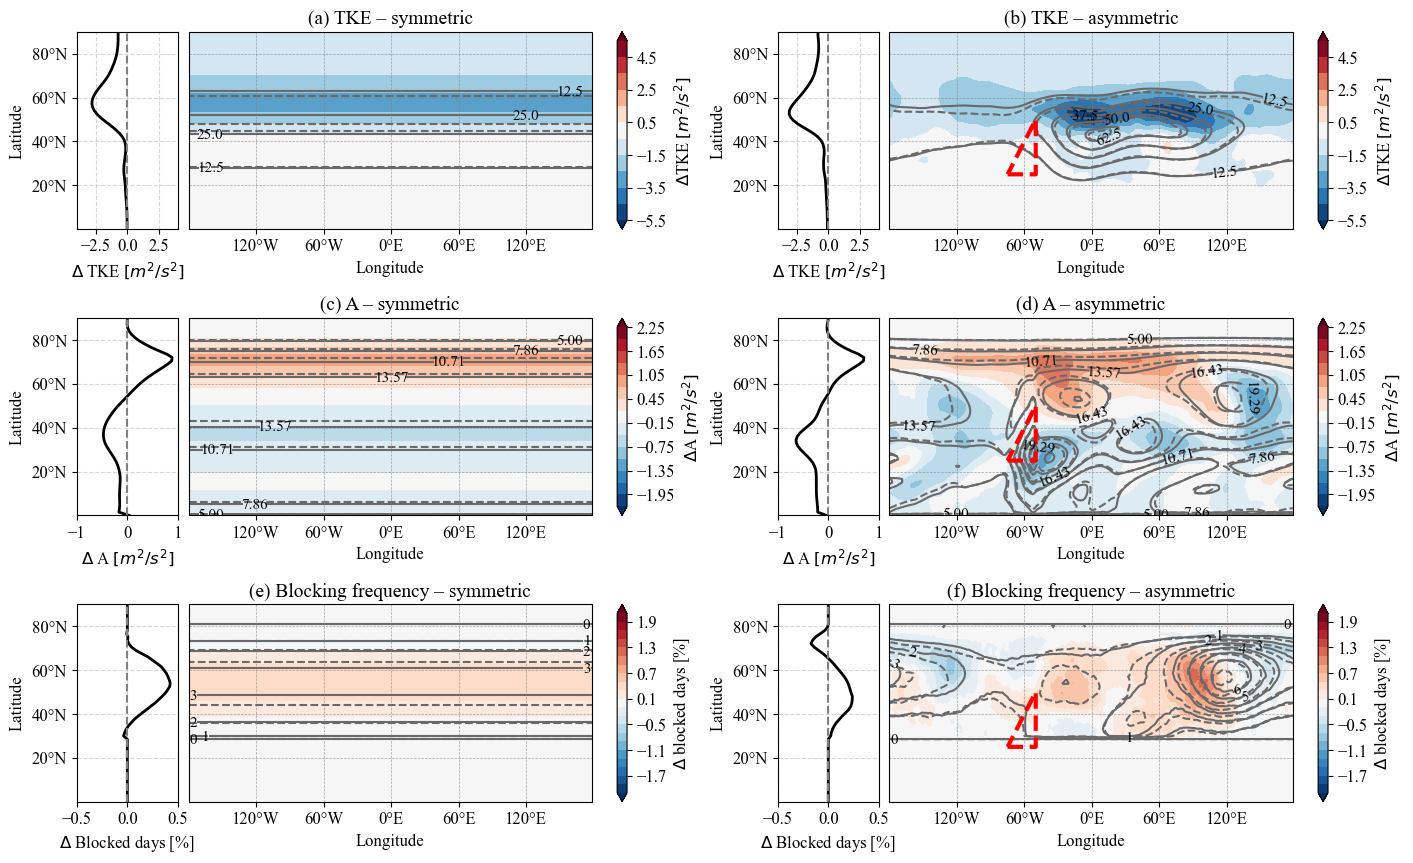

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.lines import Line2D

# --------------------------------------------------
# Global settings
# --------------------------------------------------
#plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12

fig = plt.figure(figsize=(17, 10))

# 7 columns: xsec | gap | map | big gap | xsec | gap | map
gs = gridspec.GridSpec(
    nrows=3,
    ncols=7,
    width_ratios=[1.2, 0.1, 6.0, 1, 1.2, 0.1, 6.0],
    hspace=0.45,
    wspace=0.0
)

titles  = ['symmetric', 'asymmetric']
letters = ['(a)','(c)','(e)','(b)','(d)','(f)']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

# --------------------------------------------------
# Loop over symmetric / asymmetric columns
# --------------------------------------------------
for i in range(2):

    if i == 0:
        XSEC_COL = 0
        MAP_COL  = 2
    else:
        XSEC_COL = 4
        MAP_COL  = 6

    # ---- datasets ----
    if i == 0:
        ds_a = ds_clims[0].mean('lon').broadcast_like(ds_clims[0]).transpose()
        ds_b = ds_clims[1].mean('lon').broadcast_like(ds_clims[0]).transpose()
        da_a_block = DA_clims[0].mean('lon').broadcast_like(ds_clims[0]).transpose()
        da_b_block = DA_clims[1].mean('lon').broadcast_like(ds_clims[0]).transpose()
    else:
        ds_a = ds_clims[2]
        ds_b = ds_clims[3]
        da_a_block = DA_clims[2]
        da_b_block = DA_clims[3]

    # ==================================================
    # ROW 1 — TKE
    # ==================================================
    ax_xsec = fig.add_subplot(gs[0, XSEC_COL])
    ax_map  = fig.add_subplot(gs[0, MAP_COL],
                              projection=ccrs.PlateCarree(),
                              sharey=ax_xsec)

    levels_tke = np.linspace(0, 100, 9)
    levels_tke_diff = np.arange(-5.5, 6, 1)
    xlim_tke = [-4,+4]
    
    ax_map.set_title(f'{letters[i*3]} TKE – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a.tke,
                   levels=levels_tke, colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b.tke,
                   levels=levels_tke, colors='dimgray',
                   linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=ccrs.PlateCarree())
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    sh = ax_map.contourf(ds_a.lon, ds_a.lat,
                         ds_b.tke - ds_a.tke,
                         levels=levels_tke_diff,
                         cmap='RdBu_r', extend='both')

    fig.colorbar(sh, ax=ax_map, label=r'$\Delta$TKE $[m^2/s^2]$')

    if i > 0:
        ax_map.plot(lons, lats, '--', lw=3, color='red',
                    transform=ccrs.PlateCarree())

    gl = ax_map.gridlines(draw_labels=False, linewidth=0.5,
                          color='gray', alpha=0.7, linestyle='--')

    tke_xsec = (ds_b.tke - ds_a.tke).mean('lon')

    ax_xsec.plot(tke_xsec, ds_a.lat, color='k', lw=2)
    ax_xsec.axvline(0, color='gray', ls='--')
    ax_xsec.set_ylabel('Latitude')
    ax_xsec.set_xlabel(r'$\Delta$ TKE $[m^2/s^2]$')
    ax_xsec.grid(True, ls='--', alpha=0.5)
    ax_xsec.set_yticks([20,40,60,80])
    ax_xsec.set_yticklabels(['20°N','40°N','60°N','80°N'])
    ax_xsec.set_xlim(xlim_tke)

    plt.setp(ax_map.get_yticklabels(), visible=False)

    # ==================================================
    # ROW 2 — LWA
    # ==================================================
    ax_xsec = fig.add_subplot(gs[1, XSEC_COL])
    ax_map  = fig.add_subplot(gs[1, MAP_COL],
                              projection=ccrs.PlateCarree(),
                              sharey=ax_xsec)
    
    levels_lwa = np.linspace(5, 25, 8)
    levels_lwa_diff = np.arange(-2.25, 2.3, 0.3)
    xlim_lwa = [-1, 1]  # Example, set your preferred limits
    
    ax_map.set_title(f'{letters[i*3+1]} A – {titles[i]}')
    
    # Map contours
    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a.dw_lwa,
                   levels=levels_lwa, colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b.dw_lwa,
                   levels=levels_lwa, colors='dimgray',
                   linestyles='dashed', linewidths=1.5)
    
    ax_map.clabel(c1,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

    
    sh = ax_map.contourf(ds_a.lon, ds_a.lat,
                         ds_b.dw_lwa - ds_a.dw_lwa,
                         levels=levels_lwa_diff,
                         cmap='RdBu_r', extend='both')
    
    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=ccrs.PlateCarree())
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    fig.colorbar(sh, ax=ax_map, label=r'$\Delta$A $[m^2/s^2]$')
    
    if i > 0:
        ax_map.plot(lons, lats, '--', lw=3, color='red', transform=ccrs.PlateCarree())
    
    gl = ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    
    # Cross-section
    lwa_xsec = (ds_b.dw_lwa - ds_a.dw_lwa).mean('lon')
    
    ax_xsec.plot(lwa_xsec, ds_a.lat, color='k', lw=2)
    ax_xsec.axvline(0, color='gray', ls='--')
    ax_xsec.set_xlabel(r'$\Delta$ A $[m^2/s^2]$')
    ax_xsec.set_ylabel('Latitude')
    ax_xsec.grid(True, ls='--', alpha=0.5)
    ax_xsec.set_xlim(xlim_lwa)
    ax_xsec.set_yticks([20,40,60,80])
    ax_xsec.set_yticklabels(['20°N','40°N','60°N','80°N'])

    plt.setp(ax_map.get_yticklabels(), visible=False)
    
    
    # ==================================================
    # ROW 3 — BLOCKING
    # ==================================================
    ax_xsec = fig.add_subplot(gs[2, XSEC_COL])
    ax_map  = fig.add_subplot(gs[2, MAP_COL],
                              projection=ccrs.PlateCarree(),
                              sharey=ax_xsec)
    
    levels_block = np.arange(0, 12, 1)
    levels_block_diff = np.arange(-2.1, 2.2, 0.2)
    xlim_block = [-0.5, 0.5]  # Example, set your preferred limits

    ax_map.set_title(f'{letters[i*3+2]} Blocking frequency – {titles[i]}')
    
    # Map contours
    c1 = ax_map.contour(ds_a.lon, ds_a.lat, da_a_block,
                   levels=levels_block, colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, da_b_block,
                   levels=levels_block, colors='dimgray',
                   linestyles='dashed', linewidths=1.5)

    ax_map.clabel(c1,  inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

    sh = ax_map.contourf(ds_a.lon, ds_a.lat,
                         da_b_block - da_a_block,
                         levels=levels_block_diff,
                         cmap='RdBu_r', extend='both')
    
    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=ccrs.PlateCarree())
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')
    
    fig.colorbar(sh, ax=ax_map, label=r'$\Delta$ blocked days [%]')
    
    if i > 0:
        ax_map.plot(lons, lats, '--', lw=3, color='red', transform=ccrs.PlateCarree())
    
    gl = ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    
    # Cross-section
    block_xsec = (da_b_block - da_a_block).mean('lon')
    
    ax_xsec.plot(block_xsec, ds_a.lat, color='k', lw=2)
    ax_xsec.axvline(0, color='gray', ls='--')
    ax_xsec.set_xlabel(r'$\Delta$ Blocked days [%]')
    ax_xsec.set_ylabel('Latitude')
    ax_xsec.grid(True, ls='--', alpha=0.5)
    ax_xsec.set_xlim(xlim_block)
    ax_xsec.set_yticks([20,40,60,80])
    ax_xsec.set_yticklabels(['20°N','40°N','60°N','80°N'])
    
    plt.setp(ax_map.get_yticklabels(), visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure5_wxsec.png',
            dpi=500, bbox_inches='tight')
plt.show()


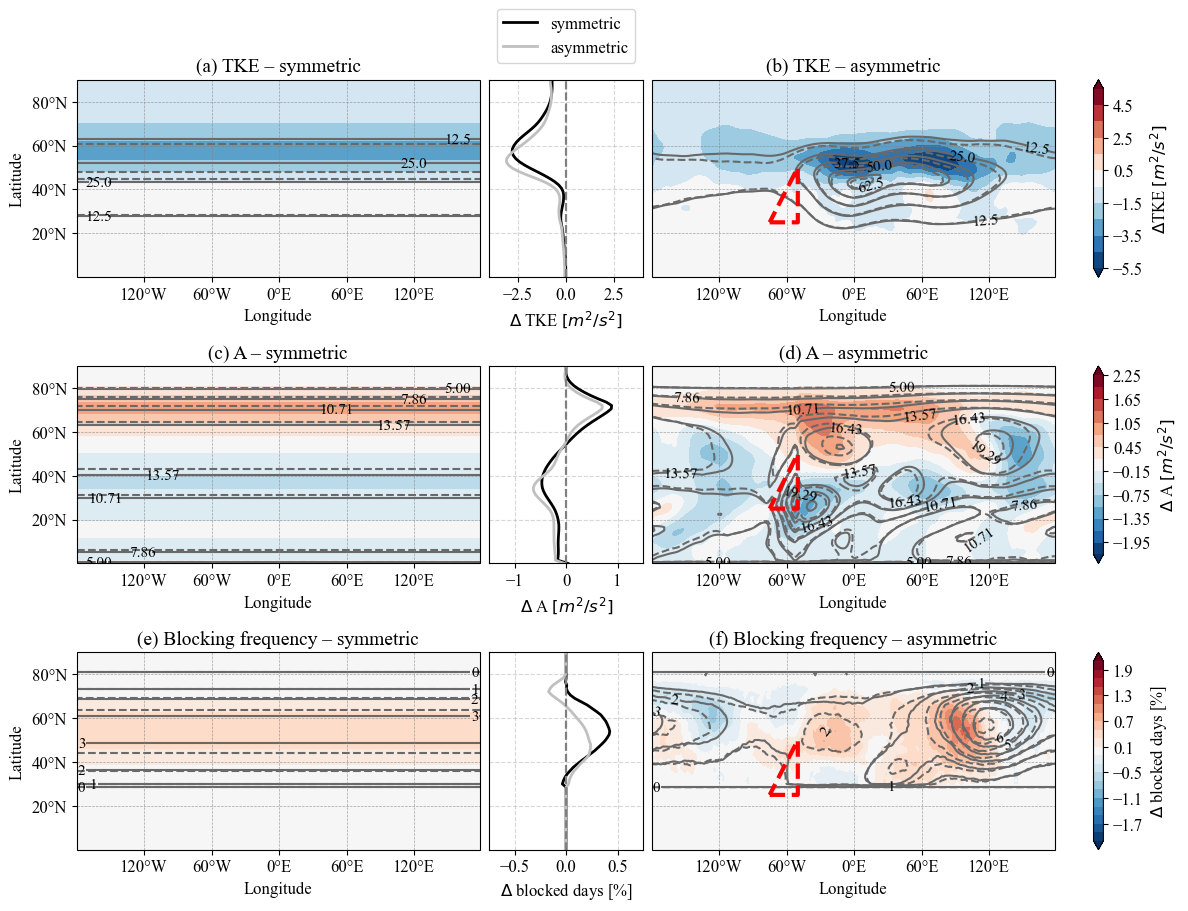

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs

plt.rcParams['font.size'] = 12

fig = plt.figure(figsize=(17, 10))
gs = gridspec.GridSpec(nrows=3, ncols=5,
                       width_ratios=[6.0, 0.25, 1.2, 0.01, 6.0],
                       hspace=0.45, wspace=-0.3)

titles  = ['symmetric', 'asymmetric']
letters = ['(a)','(c)','(e)','(b)','(d)','(f)']
colors = ['k','silver']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)
lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Precompute mean/broadcast outside the loop
# --------------------------------------------------
ds_a_list = [ds_clims[0].mean('lon').broadcast_like(ds_clims[0]).transpose(),
             ds_clims[2]]
ds_b_list = [ds_clims[1].mean('lon').broadcast_like(ds_clims[0]).transpose(),
             ds_clims[3]]

da_a_block_list = [DA_clims[0].mean('lon').broadcast_like(ds_clims[0]).transpose(),
                   DA_clims[2]]
da_b_block_list = [DA_clims[1].mean('lon').broadcast_like(ds_clims[0]).transpose(),
                   DA_clims[3]]

# --------------------------------------------------
# Loop over symmetric/asymmetric
# --------------------------------------------------
for i in range(2):

    XSEC_COL = 2
    MAP_COL = 0 if i==0 else 4

    ds_a = ds_a_list[i]
    ds_b = ds_b_list[i]
    da_a_block = da_a_block_list[i]
    da_b_block = da_b_block_list[i]

    # ---------------- ROW 1 — TKE ----------------
    if i == 0:
        ax_xsec_TKE = fig.add_subplot(gs[0, XSEC_COL])
    ax_map  = fig.add_subplot(gs[0, MAP_COL], projection=proj, sharey=ax_xsec_TKE)

    levels_tke = np.linspace(0, 100, 9)
    levels_tke_diff = np.arange(-5.5, 6, 1)
    xlim_tke = [-4,+4]

    ax_map.set_title(f'{letters[i*3]} TKE – {titles[i]}')

    # Contours
    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a.tke, levels=levels_tke,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b.tke, levels=levels_tke,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    # Filled differences (keep contourf)
    tke_diff = ds_b.tke - ds_a.tke
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, tke_diff,
                         levels=levels_tke_diff, cmap='RdBu_r', extend='both')

    if i>0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta$TKE $[m^2/s^2]$')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    if i>0:
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

    tke_xsec = tke_diff.mean('lon').values
    ax_xsec_TKE.plot(tke_xsec, ds_a.lat.values, color=colors[i], lw=2, label = titles[i])
    ax_xsec_TKE.axvline(0, color='gray', ls='--')
    ax_xsec_TKE.set_xlabel(r'$\Delta$ TKE $[m^2/s^2]$')
    ax_xsec_TKE.grid(True, ls='--', alpha=0.5)
    ax_xsec_TKE.set_xlim(xlim_tke)
    ax_xsec_TKE.legend(loc='upper right', bbox_to_anchor=(1.0,1.4))
    ax_xsec_TKE.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_TKE.get_yticklabels(), visible=False)

    # ---------------- ROW 2 — LWA ----------------
    if i == 0:
        ax_xsec_lwa = fig.add_subplot(gs[1, XSEC_COL])
    ax_map  = fig.add_subplot(gs[1, MAP_COL], projection=proj, sharey=ax_xsec_lwa)

    levels_lwa = np.linspace(5, 25, 8)
    levels_lwa_diff = np.arange(-2.25, 2.3, 0.3)
    xlim_lwa = [-1.5, 1.5]

    ax_map.set_title(f'{letters[i*3+1]} A – {titles[i]}')

    # Contours
    c1 = ax_map.contour(ds_a.lon, ds_a.lat, ds_a.dw_lwa, levels=levels_lwa,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, ds_b.dw_lwa, levels=levels_lwa,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    # Filled differences (keep contourf)
    tke_diff = ds_b.dw_lwa - ds_a.dw_lwa
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, tke_diff,
                         levels=levels_lwa_diff, cmap='RdBu_r', extend='both')

    if i>0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta$ A $[m^2/s^2]$')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    if i>0:
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

    tke_xsec = tke_diff.mean('lon').values
    ax_xsec_lwa.plot(tke_xsec, ds_a.lat.values, color=colors[i], lw=2, label = titles[i])
    ax_xsec_lwa.axvline(0, color='gray', ls='--')
    ax_xsec_lwa.set_xlabel(r'$\Delta$ A $[m^2/s^2]$')
    ax_xsec_lwa.grid(True, ls='--', alpha=0.5)
    ax_xsec_lwa.set_xlim(xlim_lwa)
    ax_xsec_lwa.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_lwa.get_yticklabels(), visible=False)

    # ---------------- ROW 3 — BLOCKING ----------------
    if i == 0:
        ax_xsec_block = fig.add_subplot(gs[2, XSEC_COL])
    ax_map  = fig.add_subplot(gs[2, MAP_COL], projection=proj, sharey=ax_xsec_block)

    levels_block = np.arange(0, 12, 1)
    levels_block_diff = np.arange(-2.1, 2.2, 0.2)
    xlim_block = [-0.75, 0.75]

    ax_map.set_title(f'{letters[i*3+2]} Blocking frequency – {titles[i]}')

    # Contours
    c1 = ax_map.contour(ds_a.lon, ds_a.lat, da_a_block, levels=levels_block,
                        colors='dimgray', linewidths=1.5)
    ax_map.contour(ds_b.lon, ds_b.lat, da_b_block, levels=levels_block,
                   colors='dimgray', linestyles='dashed', linewidths=1.5)
    ax_map.clabel(c1, inline=True, colors='black', fontsize=11)

    # Filled differences (keep contourf)
    tke_diff = da_b_block - da_a_block
    sh = ax_map.contourf(ds_a.lon, ds_a.lat, tke_diff,
                         levels=levels_block_diff, cmap='RdBu_r', extend='both')

    if i>0:
        fig.colorbar(sh, ax=ax_map, label=r'$\Delta$ blocked days [%]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120], crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)

    if i>0:
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

    tke_xsec = tke_diff.mean('lon').values
    ax_xsec_block.plot(tke_xsec, ds_a.lat.values, color=colors[i], lw=2, label = titles[i])
    ax_xsec_block.axvline(0, color='gray', ls='--')
    ax_xsec_block.set_xlabel(r'$\Delta$ blocked days [%]')
    ax_xsec_block.grid(True, ls='--', alpha=0.5)
    ax_xsec_block.set_xlim(xlim_block)
    ax_xsec_block.tick_params(axis='y', length=0)
    plt.setp(ax_xsec_block.get_yticklabels(), visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure5_wxsec.png', dpi=200, bbox_inches='tight')  # faster for testing
plt.show()